In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files

uploaded = files.upload()

csv_files = [
    name for name in uploaded
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload the dataset's CSV file.")

df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Dataset shape: (111, 60)

Column names:
['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


,Country,1965,1966,1967,1968,1969,1970,1971,1972,1973,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Canada,5.00,5.32,5.57,5.92,6.28,6.73,6.94,7.47,8.11,...,14.43,14.47,14.34,14.54,14.72,14.64,13.76,13.92,14.30,13.95
2,Mexico,1.06,1.12,1.14,1.24,1.36,1.45,1.53,1.69,1.82,...,8.03,7.94,8.11,8.26,8.15,8.07,7.35,7.83,8.18,8.45
3,US,51.98,54.89,56.80,60.19,63.30,65.54,66.92,70.25,73.22,...,93.59,92.69,92.62,92.97,96.37,95.68,88.64,93.44,95.42,94.28
4,Total North America,58.04,61.33,63.51,67.36,70.95,73.72,75.39,79.41,83.16,...,116.04,115.10,115.07,115.76,119.25,118.40,109.75,115.20,117.90,116.68


In [ ]:
print(df.columns.tolist())



['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [ ]:

# STEP 2: DATA CLEANING AND COUNTRY SELECTION

import pandas as pd
import numpy as np

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Identify year columns (1965, 1966, ..., 2023)
year_columns = [
    col for col in df.columns
    if col.isdigit() and len(col) == 4
]

if "Country" not in df.columns:
    raise ValueError("Country column not found.")

if not year_columns:
    raise ValueError("Year columns were not found.")

print("Year range in dataset:",
      year_columns[0], "to", year_columns[-1])

# Select the country exactly as named in your dataset
country_name = "US"

selected = df[
    df["Country"].astype(str).str.strip().str.lower()
    == country_name.lower()
].copy()

if selected.empty:
    raise ValueError(
        "US was not found. Check the available country names."
    )

# Convert wide format into long format
data = selected.melt(
    id_vars=["Country"],
    value_vars=year_columns,
    var_name="year",
    value_name="energy"
)

# Convert values to numeric
data["year"] = pd.to_numeric(data["year"], errors="coerce")
data["energy"] = pd.to_numeric(data["energy"], errors="coerce")

# Handle missing and invalid values
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["year"])
data["year"] = data["year"].astype(int)
data["energy"] = data["energy"].where(data["energy"] >= 0)

# Sort chronologically and remove duplicate years
data = (
    data.groupby("year", as_index=False)["energy"]
    .mean()
    .sort_values("year")
)

# Interpolate only missing values between known years
data["energy"] = data["energy"].interpolate(
    method="linear",
    limit_area="inside"
)

# Remove any remaining missing values
data = data.dropna(subset=["energy"]).reset_index(drop=True)

if len(data) < 20:
    raise ValueError(
        "Too few valid yearly records for forecasting."
    )

# Verify that years are consecutive
assert data["year"].diff().dropna().eq(1).all(), (
    "There are gaps in the yearly records."
)

print("\nData cleaning completed successfully!")
print("Selected country:", country_name)
print("Valid records:", len(data))
print("First year:", data["year"].min())
print("Last year:", data["year"].max())
print("\nFirst 5 records:")
display(data.head())

print("\nLast 5 records:")
display(data.tail())


Year range in dataset: 1965 to 2023

Data cleaning completed successfully!
Selected country: US
Valid records: 59
First year: 1965
Last year: 2023

First 5 records:


,year,energy
0,1965,51.98
1,1966,54.89
2,1967,56.80
3,1968,60.19
4,1969,63.30



Last 5 records:


,year,energy
54,2019,95.68
55,2020,88.64
56,2021,93.44
57,2022,95.42
58,2023,94.28


In [ ]:

# STEP 3: NORMALIZATION AND SEQUENCE CREATION

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Extract energy values
values = data["energy"].values.reshape(-1, 1)

# Chronological 80% training and 20% testing split
split_index = int(len(values) * 0.80)

# Normalize using only training data
scaler = MinMaxScaler()
scaler.fit(values[:split_index])
scaled_values = scaler.transform(values)

# Use previous 5 years to predict the next year
look_back = 5
X, y, target_indices = [], [], []

for i in range(look_back, len(scaled_values)):
    X.append(scaled_values[i-look_back:i, 0])
    y.append(scaled_values[i, 0])
    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

# LSTM input shape: samples, time steps, features
X = X.reshape(X.shape[0], X.shape[1], 1)

# Separate train and test sequences by target year
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

test_years = data["year"].values[target_indices[test_mask]]

print("Training sequences:", X_train.shape[0])
print("Testing sequences:", X_test.shape[0])
print("Input shape:", X_train.shape)
print("Test years:", test_years[0], "to", test_years[-1])


Training sequences: 42
Testing sequences: 12
Input shape: (42, 5, 1)
Test years: 2012 to 2023


In [ ]:

# STEP 4: BUILD AND TRAIN LSTM MODEL

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(look_back, 1)),
    LSTM(32, activation="tanh"),
    Dropout(0.1),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=150,
    batch_size=8,
    validation_split=0.15,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")
model.summary()



Epoch 1/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - loss: 0.3562 - mae: 0.5697 - val_loss: 0.6668 - val_mae: 0.8149
Epoch 2/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.2959 - mae: 0.5161 - val_loss: 0.5572 - val_mae: 0.7447
Epoch 3/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.2481 - mae: 0.4699 - val_loss: 0.4541 - val_mae: 0.6719
Epoch 4/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1939 - mae: 0.4144 - val_loss: 0.3569 - val_mae: 0.5951
Epoch 5/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.1443 - mae: 0.3543 - val_loss: 0.2653 - val_mae: 0.5124
Epoch 6/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.1033 - mae: 0.2942 - val_loss: 0.1748 - val_mae: 0.4148
Epoch 7/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0618 - mae: 0.2237 - val_loss: 0.0924 - val_mae: 0.2992
Epoch 8/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0243 - mae: 0.1322 - val_loss: 0.0334 - val_mae: 0.1746
Epoch 9/150
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.0096 - mae: 

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,693 (57.40 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,796 (38.27 KB)

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict test data
pred_scaled = model.predict(X_test, verbose=0)

# Convert normalized values back to original scale
y_test_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

y_pred_actual = scaler.inverse_transform(
    pred_scaled
).ravel()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")


MAE: 1.8079
RMSE: 2.3042


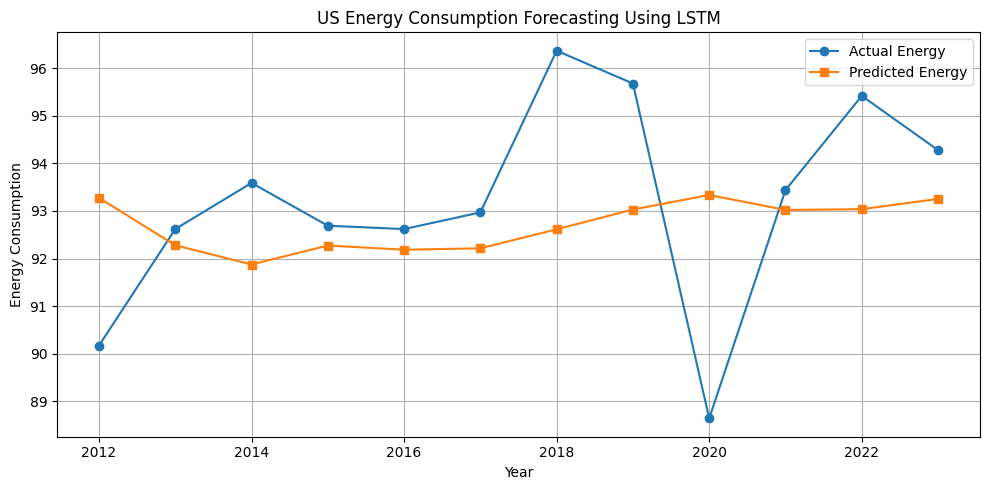

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(test_years, y_test_actual,
         marker="o", label="Actual Energy")

plt.plot(test_years, y_pred_actual,
         marker="s", label="Predicted Energy")

plt.title("US Energy Consumption Forecasting Using LSTM")
plt.xlabel("Year")
plt.ylabel("Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Calculate MAPE and approximate forecasting accuracy

from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(
    y_test_actual, y_pred_actual
) * 100

approx_accuracy = 100 - mape

print(f"MAPE: {mape:.2f}%")
print(f"Approximate Forecasting Accuracy: {approx_accuracy:.2f}%")


MAPE: 1.95%
Approximate Forecasting Accuracy: 98.05%


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Predict all unseen test sequences
pred_scaled = model.predict(X_test, verbose=0)

# Convert predictions back to original scale
predictions = scaler.inverse_transform(
    pred_scaled
).ravel()

actual_values = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

# Show one test example
i = 0

print("Test year:", test_years[i])
print("Actual energy value:", round(actual_values[i], 2))
print("Predicted energy value:", round(predictions[i], 2))
print("Absolute error:", round(abs(actual_values[i] - predictions[i]), 2))

# Evaluate the entire test set
mae = mean_absolute_error(actual_values, predictions)
rmse = np.sqrt(mean_squared_error(actual_values, predictions))

print("\nOverall Test Results")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

Test year: 2012
Actual energy value: 90.17
Predicted energy value: 93.28
Absolute error: 3.11

Overall Test Results
MAE: 1.8079
RMSE: 2.3042


In [11]:

import numpy as np

# Get 5 consecutive yearly energy values from the user
print("Enter energy values for 5 consecutive years:")

user_values = []

for i in range(1, 6):
    value = float(input(f"Enter Year {i} energy value: "))
    user_values.append(value)

# Convert input into the correct shape
user_data = np.array(user_values).reshape(5, 1)

# Scale using the scaler fitted during training
user_scaled = scaler.transform(user_data)

# LSTM input shape: (1 sample, 5 time steps, 1 feature)
user_scaled = user_scaled.reshape(1, 5, 1)

# Predict the next year's energy value
pred_scaled = model.predict(user_scaled, verbose=0)

# Convert prediction back to the original scale
predicted_energy = scaler.inverse_transform(
    pred_scaled
)[0, 0]

print("\n========== PREDICTION RESULT ==========")
print("Input energy values:", user_values)
print("Predicted next-year energy value:",
      round(float(predicted_energy), 2))


Enter energy values for 5 consecutive years:
Enter Year 1 energy value: 3456
Enter Year 2 energy value: 45678
Enter Year 3 energy value: 456
Enter Year 4 energy value: 45678
Enter Year 5 energy value: 456

========== PREDICTION RESULT ==========
Input energy values: [3456.0, 45678.0, 456.0, 45678.0, 456.0]
Predicted next-year energy value: 127.72
